Dataset Generated Successfully!
Input Shape: (1500, 50, 1)
Target Shape: (1500,)
Total Samples: 1500
Time Steps: 50


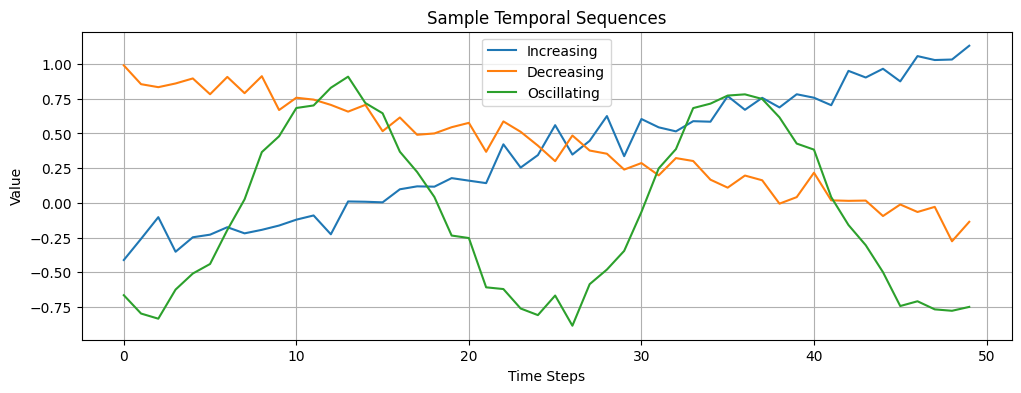


Training Samples: 960
Validation Samples: 240
Testing Samples: 300

RNN Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,667 (6.51 KB)

 Trainable params: 1,667 (6.51 KB)

 Non-trainable params: 0 (0.00 B)


Training RNN Model...
Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.5958 - loss: 0.9290 - val_accuracy: 0.9208 - val_loss: 0.5386
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9406 - loss: 0.3610 - val_accuracy: 0.9875 - val_loss: 0.1713
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9844 - loss: 0.1581 - val_accuracy: 0.9875 - val_loss: 0.0972
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9906 - loss: 0.1087 - val_accuracy: 1.0000 - val_loss: 0.0355
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9917 - loss: 0.0686 - val_accuracy: 1.0000 - val_loss: 0.0186
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9958 - loss: 0.0458 - val_accuracy: 0.9917 - val_loss: 0.0253
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9500 - loss: 0.1911 - val_accuracy: 0.9708 - val_loss: 0.0584
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9781 - loss: 0.0835 - v

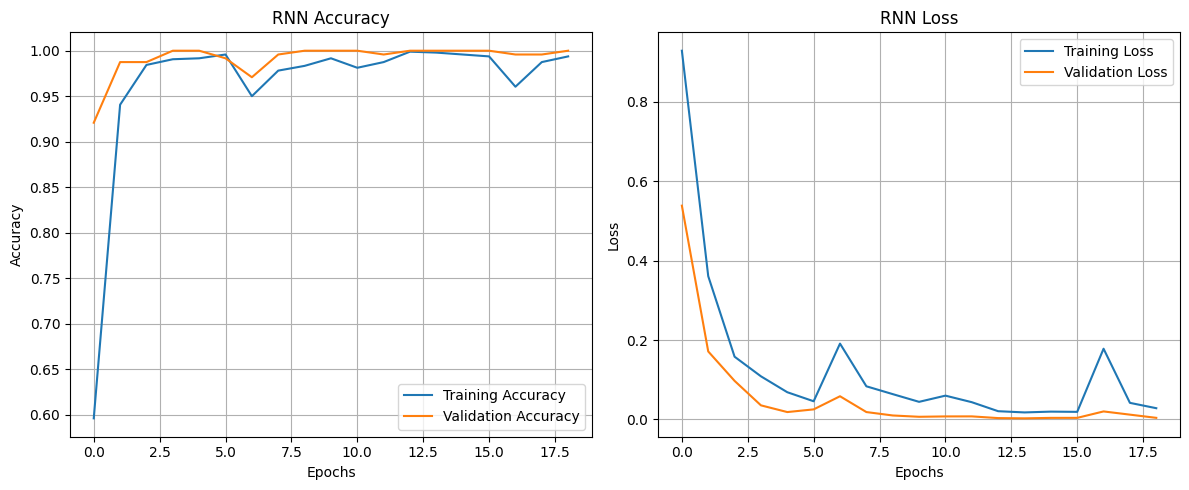

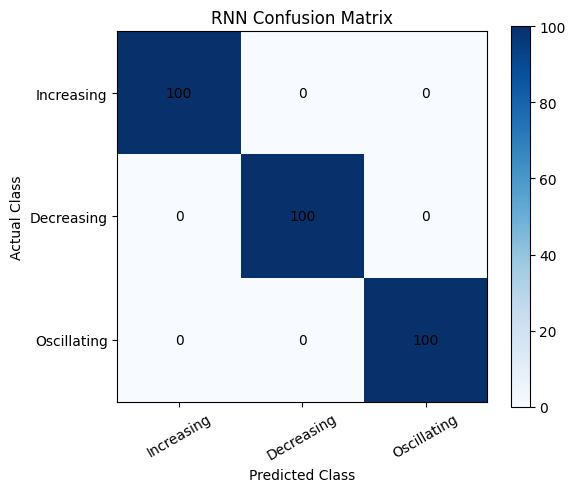

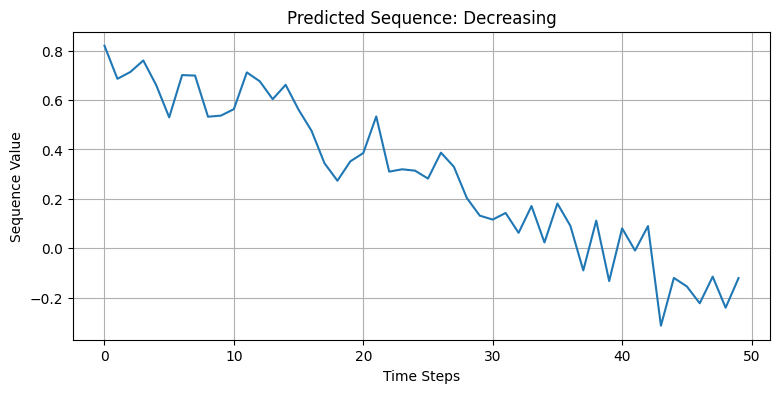


FINAL RESULT
Total Classes: 3
Time Steps: 50
RNN Units: 32
Optimizer: Adam
Test Accuracy: 100.0 %

Temporal Data Classification Completed Successfully!


In [ ]:
# DLL Experiment No. 12
# RNN for Temporal Data Classification and Sequence Modelling

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


# 1. Generate Temporal Dataset
np.random.seed(42)
tf.random.set_seed(42)

samples_per_class = 500
time_steps = 50

time = np.linspace(0, 1, time_steps)

X = []
Y = []

# Generate Increasing, Decreasing and Oscillating Sequences
for i in range(samples_per_class):

    # Class 0: Increasing Sequence
    slope = np.random.uniform(0.8, 1.5)
    start = np.random.uniform(-0.5, 0.0)

    sequence = start + slope * time
    sequence += np.random.normal(0, 0.08, time_steps)

    X.append(sequence)
    Y.append(0)


    # Class 1: Decreasing Sequence
    slope = np.random.uniform(0.8, 1.5)
    start = np.random.uniform(0.5, 1.0)

    sequence = start - slope * time
    sequence += np.random.normal(0, 0.08, time_steps)

    X.append(sequence)
    Y.append(1)


    # Class 2: Oscillating Sequence
    amplitude = np.random.uniform(0.5, 1.0)
    frequency = np.random.uniform(2, 4)
    phase = np.random.uniform(0, 2 * np.pi)

    sequence = amplitude * np.sin(
        2 * np.pi * frequency * time + phase
    )

    sequence += np.random.normal(0, 0.08, time_steps)

    X.append(sequence)
    Y.append(2)


# Convert into NumPy arrays
X = np.array(X, dtype="float32")
Y = np.array(Y, dtype="int32")

# Shuffle Dataset
indices = np.random.permutation(len(X))

X = X[indices]
Y = Y[indices]

# Reshape into RNN input format
X = X.reshape(X.shape[0], time_steps, 1)

class_names = [
    "Increasing",
    "Decreasing",
    "Oscillating"
]

print("Dataset Generated Successfully!")
print("Input Shape:", X.shape)
print("Target Shape:", Y.shape)
print("Total Samples:", len(X))
print("Time Steps:", time_steps)


# 2. Visualize Sample Sequences
plt.figure(figsize=(12, 4))

for class_id in range(3):

    sample_index = np.where(Y == class_id)[0][0]

    plt.plot(
        X[sample_index].flatten(),
        label=class_names[class_id]
    )

plt.title("Sample Temporal Sequences")
plt.xlabel("Time Steps")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()


# 3. Split Dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

# Split Training Data into Training and Validation
X_train, X_val, Y_train, Y_val = train_test_split(
    X_train,
    Y_train,
    test_size=0.2,
    random_state=42,
    stratify=Y_train
)

print("\nTraining Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))


# 4. Build Simple RNN Model
model = models.Sequential([

    layers.Input(shape=(time_steps, 1)),

    layers.SimpleRNN(
        32,
        activation="tanh"
    ),

    layers.Dense(
        16,
        activation="relu"
    ),

    layers.Dropout(0.2),

    layers.Dense(
        3,
        activation="softmax"
    )

])


# 5. Compile Model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nRNN Model Architecture:")
model.summary()


# 6. Train Model
print("\nTraining RNN Model...")

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

print("\nRNN Training Completed Successfully!")


# 7. Evaluate Model
test_loss, test_accuracy = model.evaluate(
    X_test,
    Y_test,
    verbose=0
)

print("\n================================")
print("MODEL PERFORMANCE")
print("================================")

print("Test Loss:", round(test_loss, 4))

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)


# 8. Make Predictions
predictions = model.predict(
    X_test,
    verbose=0
)

predicted_classes = np.argmax(
    predictions,
    axis=1
)


# 9. Classification Report
print("\nClassification Report:")

print(
    classification_report(
        Y_test,
        predicted_classes,
        target_names=class_names
    )
)


# 10. Predict Random Sequence
sample_index = np.random.randint(
    0, len(X_test)
)

test_sequence = X_test[sample_index]

actual_class = Y_test[sample_index]

prediction = model.predict(
    np.expand_dims(test_sequence, axis=0),
    verbose=0
)[0]

predicted_class = np.argmax(prediction)

confidence = np.max(prediction) * 100


print("\n================================")
print("TEMPORAL SEQUENCE PREDICTION")
print("================================")

print("Actual Class:", class_names[actual_class])

print("Predicted Class:", class_names[predicted_class])

print("Confidence:", round(float(confidence), 2), "%")


# 11. Display Class Probabilities
print("\nClass Probabilities:")

for name, probability in zip(class_names, prediction):

    print(
        name,
        ":",
        round(float(probability * 100), 2),
        "%"
    )


# 12. Plot Training and Validation Accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("RNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)


# 13. Plot Training and Validation Loss
plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("RNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# 14. Confusion Matrix
cm = confusion_matrix(
    Y_test,
    predicted_classes
)

plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(
    range(3),
    class_names,
    rotation=30
)

plt.yticks(
    range(3),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("RNN Confusion Matrix")

for i in range(3):
    for j in range(3):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()


# 15. Display Random Sequence
plt.figure(figsize=(9, 4))

plt.plot(test_sequence.flatten())

plt.title(
    "Predicted Sequence: " + class_names[predicted_class]
)

plt.xlabel("Time Steps")
plt.ylabel("Sequence Value")

plt.grid(True)
plt.show()


# 16. Final Result
print("\n================================")
print("FINAL RESULT")
print("================================")

print("Total Classes:", len(class_names))

print("Time Steps:", time_steps)

print("RNN Units: 32")

print("Optimizer: Adam")

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

print("\nTemporal Data Classification Completed Successfully!")